# Diabetes Binary Health Indicators Analysis
## BRFSS 2015 Dataset

This notebook performs a comprehensive analysis of the diabetes dataset, including:
- Data exploration and visualization
- Handling missing values
- Feature selection
- Machine learning model training and evaluation



## 1. Import Required Libraries

In [1]:
#!pip install plotly
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Machine learning - preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning - models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Machine learning - evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve
)

# Warnings
import warnings
warnings.filterwarnings('ignore')

## 1.1 Import Custom Functions

In [2]:
# Import custom functions from functions.py
from functions import (
    load_and_explore_data,
    visualize_target_distribution,
    balance_data_smote,
    plot_confusion_matrix,
    heatmap,
    permutation_importance_numpy,
    select_k_best_important_features,
    evaluate_model,
    compare_models,
    knn_crossval,
    random_forest_tune_parameters,
    training,
    evaluation
)

print(" Custom functions imported successfully!")

 Custom functions imported successfully!


## 2. Load and Explore the Dataset

In [3]:
# Load the diabetes dataset using custom function
df = load_and_explore_data('diabetes_binary_health_indicators_BRFSS2015.csv',
                           target_column='Diabetes_binary')

Dataset loaded successfully!
Shape: (253680, 22)

Number of samples: 253,680
Number of features: 22

 No missing values found

Target Variable Distribution (Diabetes_binary):
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Percentage Distribution:
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


In [4]:
# Display first few rows
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
# Dataset information
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 no

In [6]:
# Statistical summary
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [7]:
# Check for missing values
print("Missing Values:")
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Percentage': missing_percentage
})
missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

Missing Values:


,Missing Count,Percentage


In [8]:
# Check class distribution
print("Target Variable Distribution (Diabetes_binary):")
print(df['Diabetes_binary'].value_counts())
print("\nPercentage Distribution:")
print(df['Diabetes_binary'].value_counts(normalize=True) * 100)

Target Variable Distribution (Diabetes_binary):
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Percentage Distribution:
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


## 3. Data Visualization

In [9]:
# Visualize target variable distribution using custom function
visualize_target_distribution(df)

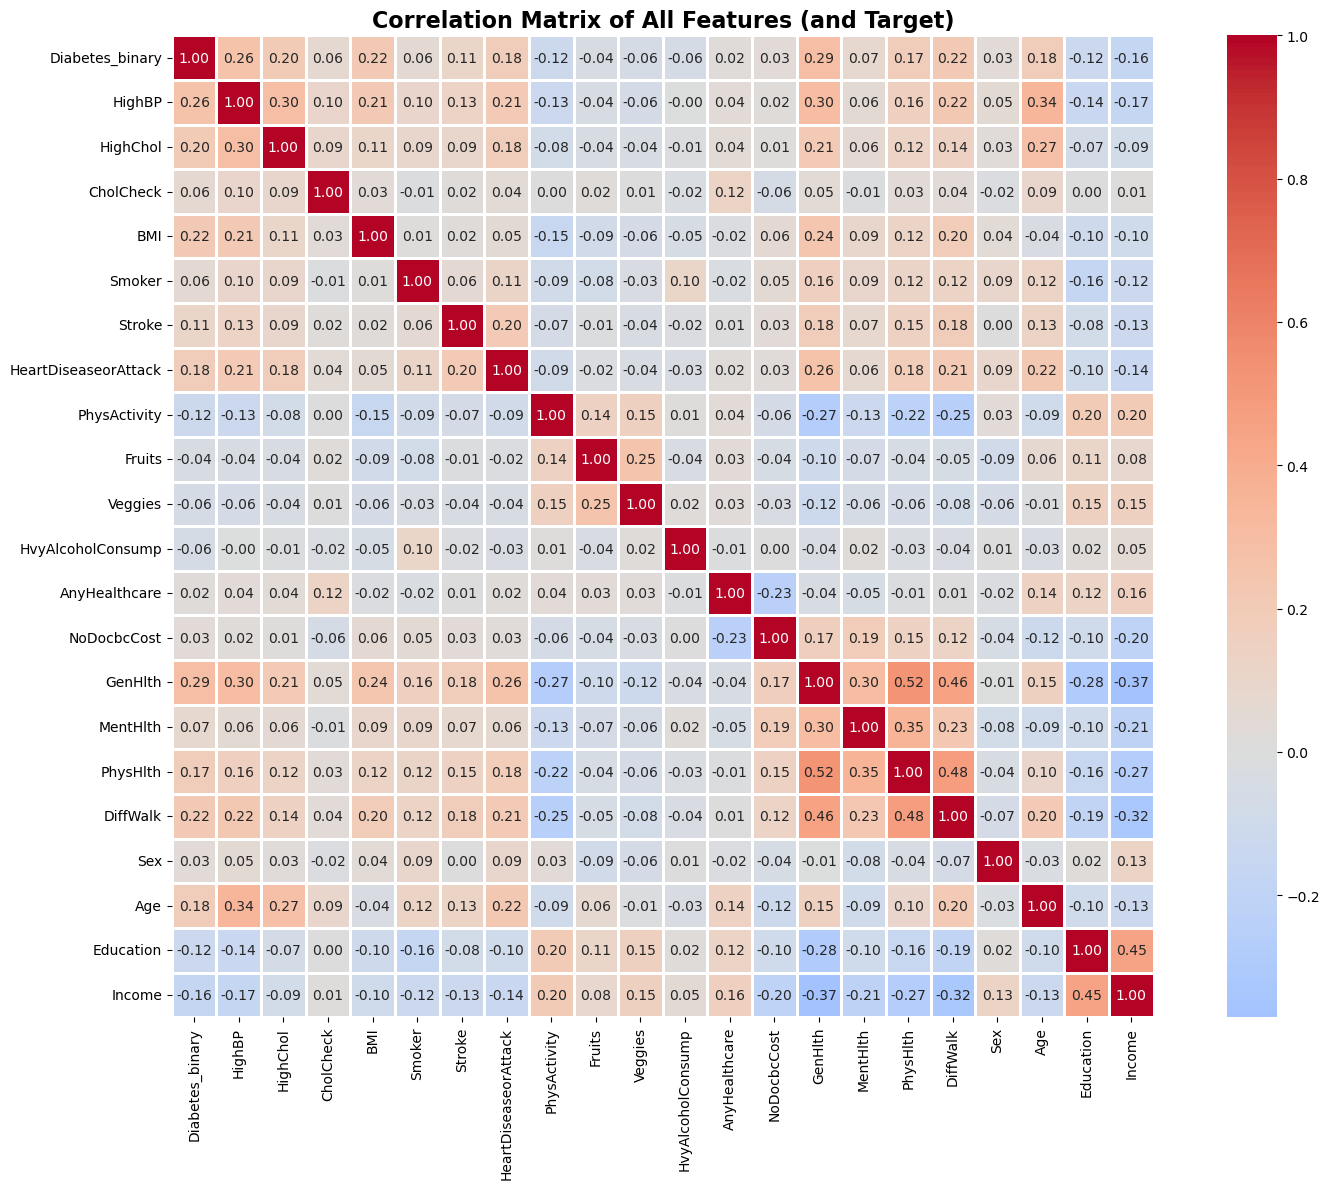

In [10]:
# Correlation heatmap using custom function
heatmap(df)

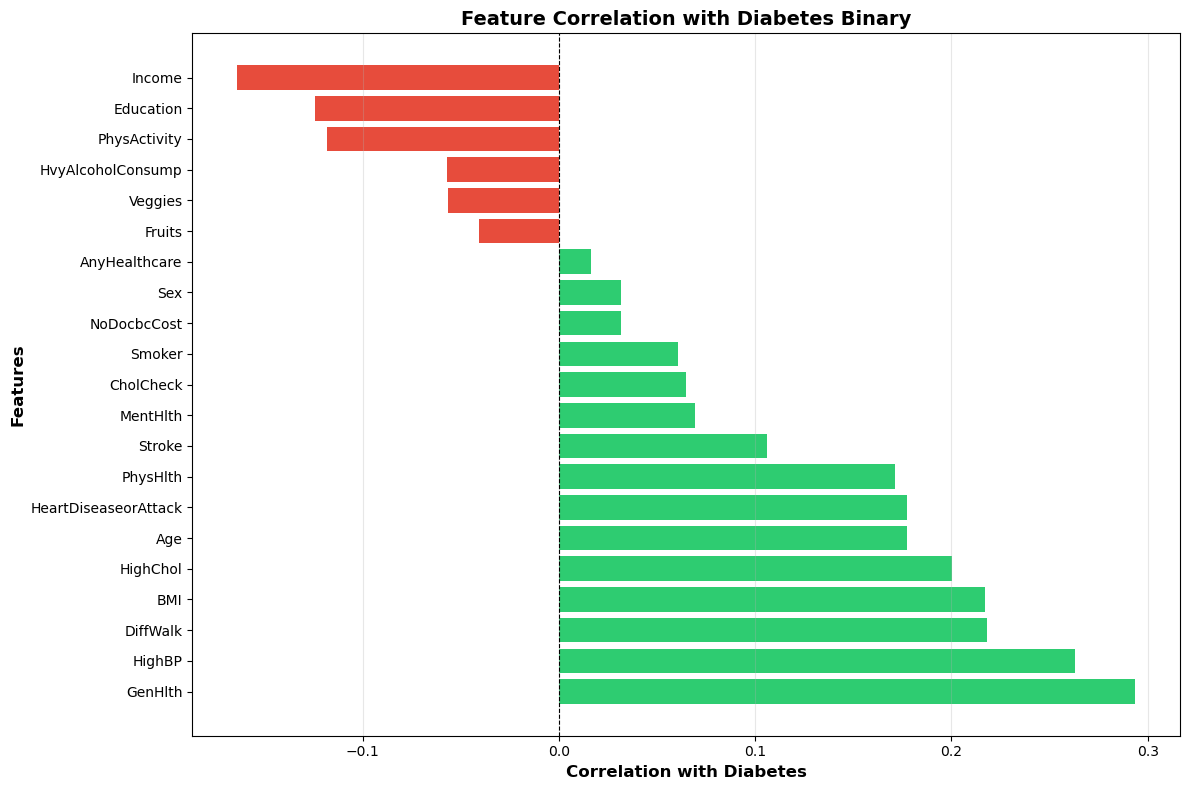

Top 10 Most Correlated Features:
GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Stroke                  0.105816
MentHlth                0.069315
Name: Diabetes_binary, dtype: float64


In [11]:
# Feature correlation with target variable
correlation_matrix = df.corr()
target_corr = correlation_matrix['Diabetes_binary'].drop('Diabetes_binary').sort_values(ascending=False)

plt.figure(figsize=(12, 8))
colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in target_corr.values]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.xlabel('Correlation with Diabetes', fontsize=12, fontweight='bold')
plt.ylabel('Features', fontsize=12, fontweight='bold')
plt.title('Feature Correlation with Diabetes Binary', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 Most Correlated Features:")
print(target_corr.head(10))

## 4. Feature Engineering

### 4.1 Separate Features and Target

In [12]:
# Separate features and target
X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nFeature columns:")
print(X.columns.tolist())

Features shape: (253680, 21)
Target shape: (253680,)

Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [13]:
# Analyze class imbalance
print("Class Imbalance Analysis:")
class_counts = y.value_counts()
class_percentages = y.value_counts(normalize=True) * 100

print(f"\nNo Diabetes (0): {class_counts[0]:,} samples ({class_percentages[0]:.2f}%)")
print(f"Diabetes (1): {class_counts[1]:,} samples ({class_percentages[1]:.2f}%)")

imbalance_ratio = class_counts[0] / class_counts[1]
print(f"\nImbalance Ratio: {imbalance_ratio:.2f}:1")


Class Imbalance Analysis:

No Diabetes (0): 218,334 samples (86.07%)
Diabetes (1): 35,346 samples (13.93%)

Imbalance Ratio: 6.18:1


## 5. Data Preprocessing and Handling Class Imbalance

### 5.1 Split Data into Training and Testing Sets

In [14]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]:,} samples")
print(f"Testing set size: {X_test.shape[0]:,} samples")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nPercentage distribution:")
print(y_train.value_counts(normalize=True) * 100)

Training set size: 202,944 samples
Testing set size: 50,736 samples

Training set class distribution:
Diabetes_binary
0.0    174667
1.0     28277
Name: count, dtype: int64

Percentage distribution:
Diabetes_binary
0.0    86.0666
1.0    13.9334
Name: proportion, dtype: float64


### 5.2 Feature Scaling

In [15]:
# Feature scaling on balanced data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for easier manipulation
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Feature scaling completed!")
print(f"\nScaled training data shape: {X_train_scaled.shape}")
print(f"Scaled testing data shape: {X_test_scaled.shape}")

Feature scaling completed!

Scaled training data shape: (202944, 21)
Scaled testing data shape: (50736, 21)


### 5.3 Handle Class Imbalance with SMOTE

In [16]:
# Apply SMOTE using custom function
print("Applying SMOTE to balance the training data...")

print(f"\nOriginal training set:")
print(f"  Shape: {X_train_scaled.shape}")
print(f"  Class 0: {(y_train == 0).sum():,}")
print(f"  Class 1: {(y_train == 1).sum():,}")

X_train_balanced, y_train_balanced = balance_data_smote(X_train_scaled, y_train, random_state=42)

print(f"\nBalanced training set (after SMOTE):")
print(f"  Shape: {X_train_balanced.shape}")
print(f"  Class 0: {(y_train_balanced == 0).sum():,}")
print(f"  Class 1: {(y_train_balanced == 1).sum():,}")

print("\n Training data balanced ")

Applying SMOTE to balance the training data...

Original training set:
  Shape: (202944, 21)
  Class 0: 174,667
  Class 1: 28,277
 SMOTE applied: 202,944 → 349,334 samples

Balanced training set (after SMOTE):
  Shape: (349334, 21)
  Class 0: 174,667
  Class 1: 174,667

 Training data balanced 


## 6. Feature Selection Using Permutation Importance

Feature Selection using Permutation Importance:

Top 10 Features by Permutation Importance:
              Feature  Importance       Std
13            GenHlth    0.065935  0.000531
3                 BMI    0.029719  0.000330
18                Age    0.024786  0.000439
0              HighBP    0.016762  0.000427
1            HighChol    0.008637  0.000235
2           CholCheck    0.003389  0.000139
10  HvyAlcoholConsump    0.002384  0.000114
17                Sex    0.002243  0.000188
15           PhysHlth    0.001302  0.000196
20             Income    0.000505  0.000163


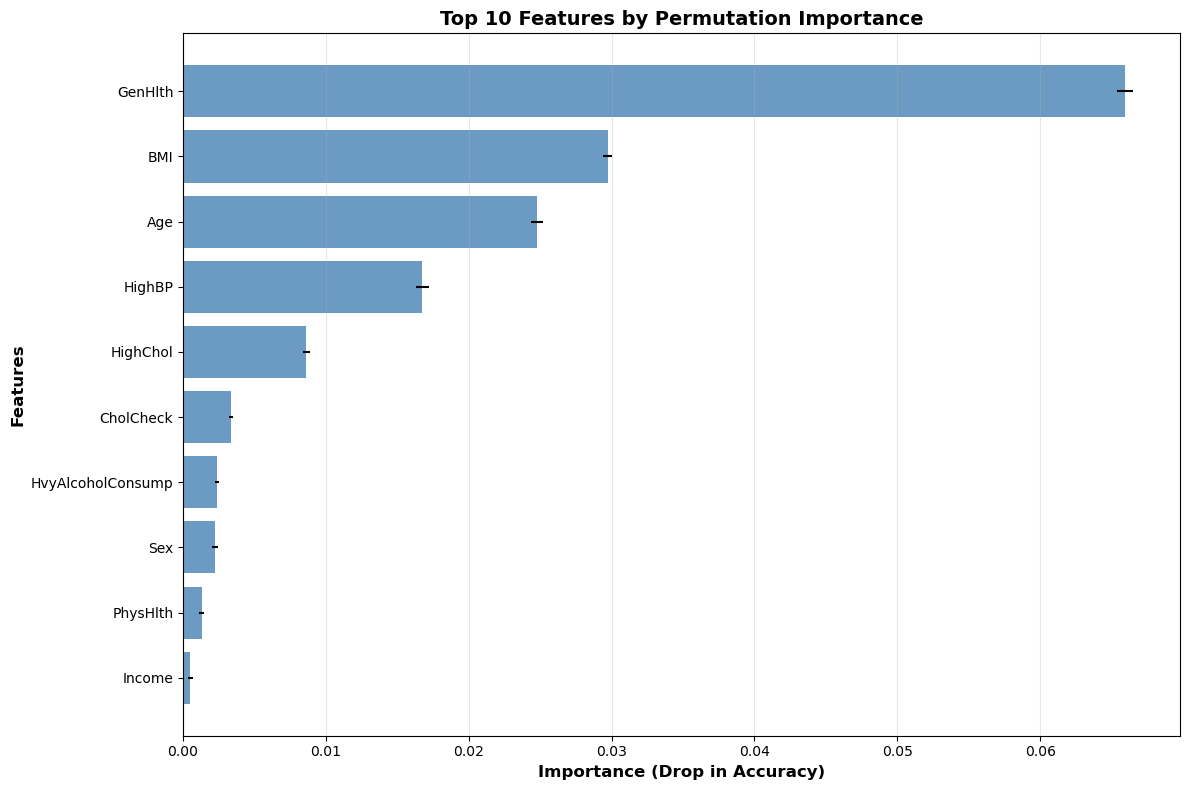

In [17]:
# Feature Selection using Permutation Importance
print("Feature Selection using Permutation Importance:")

# Create a pipeline with logistic regression for feature importance
baseline_model = Pipeline([
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

# Fit the baseline model
baseline_model.fit(X_train_balanced, y_train_balanced)

# Calculate permutation importance using custom function
importance_mean, importance_std = permutation_importance_numpy(
    baseline_model,
    X_train_balanced.values if isinstance(X_train_balanced, pd.DataFrame) else X_train_balanced,
    y_train_balanced.values if isinstance(y_train_balanced, pd.Series) else y_train_balanced,
    n_repeats=20,
    random_state=42
)

# Create DataFrame with feature importance
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance_mean,
    'Std': importance_std
}).sort_values('Importance', ascending=False)

print("\nTop 10 Features by Permutation Importance:")
print(feature_importance_df.head(10))

# Visualize feature importance
plt.figure(figsize=(12, 8))
top_10 = feature_importance_df.head(10)
plt.barh(top_10['Feature'], top_10['Importance'],
         xerr=top_10['Std'], color='steelblue', alpha=0.8)
plt.xlabel('Importance (Drop in Accuracy)', fontweight='bold', fontsize=12)
plt.ylabel('Features', fontweight='bold', fontsize=12)
plt.title('Top 10 Features by Permutation Importance', fontweight='bold', fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Select top 10 features using custom function
k = 10
X_train_selected, selected_feature_names = select_k_best_important_features(
    X_train_balanced.values if isinstance(X_train_balanced, pd.DataFrame) else X_train_balanced,
    X_train.columns.tolist(),
    importance_mean,
    k=k
)

# Convert to DataFrame for easier manipulation
X_train_selected = pd.DataFrame(X_train_selected, columns=selected_feature_names)

# Apply same feature selection to test data
X_test_selected = X_test_scaled[selected_feature_names]

print(f"\n Selected {k} most important features for modeling:")
print(selected_feature_names)
print(f"\nReduced training set shape: {X_train_selected.shape}")
print(f"Reduced testing set shape: {X_test_selected.shape}")


 Selected 10 most important features for modeling:
['GenHlth', 'BMI', 'Age', 'HighBP', 'HighChol', 'CholCheck', 'HvyAlcoholConsump', 'Sex', 'PhysHlth', 'Income']

Reduced training set shape: (349334, 10)
Reduced testing set shape: (50736, 10)


## 7. Model Training and Evaluation

In [19]:
# Dictionary to store results
results = {}

print(" Using evaluate_model function from functions.py")

 Using evaluate_model function from functions.py


### 7.1 Logistic Regression

In [20]:
# Logistic Regression using custom evaluate_model function
lr_model = LogisticRegression(random_state=42, max_iter=1000)
results['Logistic Regression'] = evaluate_model('Logistic Regression', lr_model,
                                                 X_train_selected, X_test_selected,
                                                 y_train_balanced, y_test)

Accuracy:  0.7306
Precision: 0.3104
Recall:    0.7645
F1-Score:  0.4416


### 7.2 Random Forest

In [21]:
# Random Forest using custom evaluate_model function
rf_model = RandomForestClassifier(n_estimators=10, random_state=42, max_depth=10)
results['Random Forest'] = evaluate_model('Random Forest', rf_model,
                                          X_train_selected, X_test_selected,
                                          y_train_balanced, y_test)

Accuracy:  0.7918
Precision: 0.3563
Recall:    0.6131
F1-Score:  0.4507


#### 7.2.1 Random Forest Hyperparameter Tuning

In [22]:
# Tune Random Forest hyperparameters
# The validation set is taken from the ORIGINAL training data (before SMOTE):
# the test set is NOT used for tuning
from sklearn.model_selection import train_test_split
from functions import random_forest_tune_parameters

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled[selected_feature_names], y_train,
    test_size=0.2, random_state=42, stratify=y_train
)

# SMOTE on the training part only
X_tr_bal, y_tr_bal = balance_data_smote(X_tr, y_tr)

print("Random Forest Hyperparameter Tuning")
print(f"Training part: {X_tr_bal.shape[0]:,} samples (balanced with SMOTE)")
print(f"Validation part: {X_val.shape[0]:,} samples (natural distribution)")

rf_results_df, rf_best_params = random_forest_tune_parameters(
    X_tr_bal, y_tr_bal,
    X_val, y_val,
    n_estimators_list=[1, 5, 10, 15, 20],
    max_depth_list=[5, 10, 15, 20],
    min_samples_split_list=[2, 5, 10],
    random_state=42,
    metric="recall"
)

print("Top 5 Parameter Combinations:")
print(rf_results_df.head(5).to_string(index=False))

 SMOTE applied: 162,355 → 279,466 samples
Random Forest Hyperparameter Tuning
Training part: 279,466 samples (balanced with SMOTE)
Validation part: 40,589 samples (natural distribution)
[1/60] n_est=1, max_depth=5, min_split=2: recall=0.6821
[2/60] n_est=1, max_depth=5, min_split=5: recall=0.6821
[3/60] n_est=1, max_depth=5, min_split=10: recall=0.6821
[4/60] n_est=1, max_depth=10, min_split=2: recall=0.6810
[5/60] n_est=1, max_depth=10, min_split=5: recall=0.6810
[6/60] n_est=1, max_depth=10, min_split=10: recall=0.6905
[7/60] n_est=1, max_depth=15, min_split=2: recall=0.6286
[8/60] n_est=1, max_depth=15, min_split=5: recall=0.6170
[9/60] n_est=1, max_depth=15, min_split=10: recall=0.6212
[10/60] n_est=1, max_depth=20, min_split=2: recall=0.5144
[11/60] n_est=1, max_depth=20, min_split=5: recall=0.5487
[12/60] n_est=1, max_depth=20, min_split=10: recall=0.5229
[13/60] n_est=5, max_depth=5, min_split=2: recall=0.7581
[14/60] n_est=5, max_depth=5, min_split=5: recall=0.7581
[15/60] n_es

In [23]:
# Train Random Forest with optimized parameters on full training set
rf_optimized = RandomForestClassifier(**rf_best_params, random_state=42)
results['Random Forest (Optimized)'] = evaluate_model(
    f"Random Forest (Optimized)",
    rf_optimized,
    X_train_selected, X_test_selected,
    y_train_balanced, y_test
)

Accuracy:  0.7422
Precision: 0.3134
Recall:    0.7142
F1-Score:  0.4357


### 7.3 K-Nearest Neighbors

In [24]:
# K-Nearest Neighbors using custom evaluate_model function
knn_model = KNeighborsClassifier(n_neighbors=5)
# results['K-Nearest Neighbors'] = evaluate_model('K-Nearest Neighbors', knn_model,
#                                                 X_train_selected, X_test_selected,
#                                                 y_train_balanced, y_test)

#### 7.3.1 Retrain KNN with Optimal K

K = 1: recall = 0.3667 +- 0.0048
K = 5: recall = 0.5339 +- 0.0073
K = 10: recall = 0.5872 +- 0.0027
K = 15: recall = 0.6789 +- 0.0022


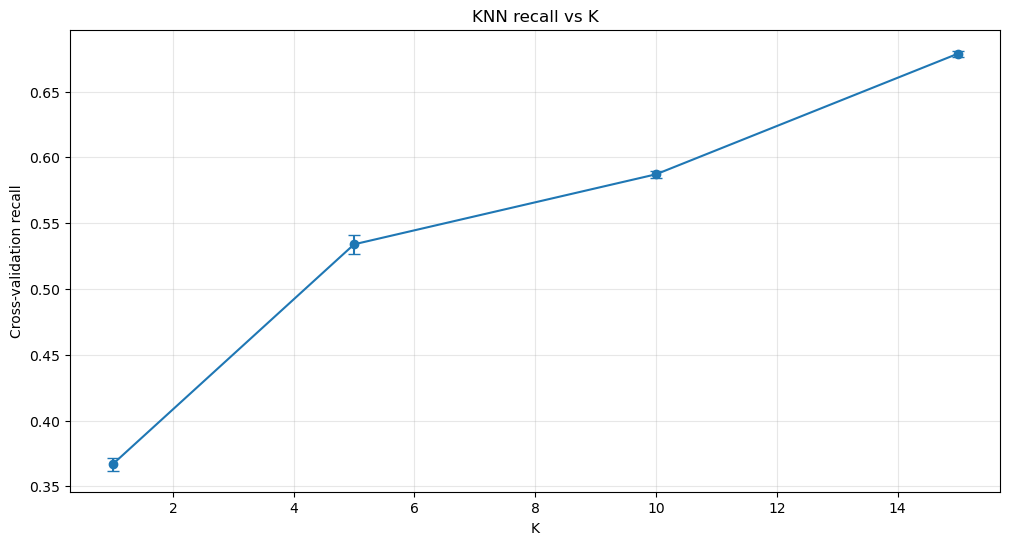


 Optimal K value: 15
   Cross-validation recall: 0.6789


In [25]:
# Find the optimal K for KNN with 5-fold cross-validation
# SMOTE is applied INSIDE each fold (training folds only), so validation folds contain only real data
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_train_sel_orig = X_train_scaled[selected_feature_names]
K = [1, 5, 10, 15]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rec_val = []

for k in K:
    pipe = ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(pipe, X_train_sel_orig, y_train, cv=cv, scoring="recall", n_jobs=-1)
    rec_val.append(scores)
    print(f"K = {k}: recall = {scores.mean():.4f} +- {scores.std():.4f}")

rec_val = np.array(rec_val)
mean_rec = rec_val.mean(axis=1)
std_rec = rec_val.std(axis=1)

# Plot validation recall vs K
plt.figure(figsize=(12, 6))
plt.errorbar(K, mean_rec, yerr=std_rec, marker='o', capsize=4)
plt.xlabel("K")
plt.ylabel("Cross-validation recall")
plt.title("KNN recall vs K")
plt.grid(alpha=0.3)
plt.show()

best_k = K[np.argmax(mean_rec)]
print(f"\n Optimal K value: {best_k}")
print(f"   Cross-validation recall: {max(mean_rec):.4f}")

In [26]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
results['K-Nearest Neighbors'] = evaluate_model('K-Nearest Neighbors', knn_model,
                                                X_train_selected, X_test_selected,
                                                y_train_balanced, y_test)

Accuracy:  0.7628
Precision: 0.3175
Recall:    0.6113
F1-Score:  0.4179


### 7.4 Naive Bayes

In [27]:
# Naive Bayes using custom evaluate_model function
nb_model = GaussianNB()
results['Naive Bayes'] = evaluate_model('Naive Bayes', nb_model,
                                        X_train_selected, X_test_selected,
                                        y_train_balanced, y_test)

Accuracy:  0.6481
Precision: 0.2616
Recall:    0.8368
F1-Score:  0.3985


### 7.5 Neural Network (MLP)

In [28]:
# Prepare dataset for PyTorch neural network
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_selected.values)
y_train_tensor = torch.LongTensor(y_train_balanced.values)
X_test_tensor = torch.FloatTensor(X_test_selected.values)
y_test_tensor = torch.LongTensor(y_test.values)

print(f"Training data shape: {X_train_tensor.shape}")
print(f"Training labels shape: {y_train_tensor.shape}")
print(f"Test data shape: {X_test_tensor.shape}")
print(f"Test labels shape: {y_test_tensor.shape}")

# Split training data into train and validation sets for neural network
train_size = int(0.8 * len(X_train_tensor))
val_size = len(X_train_tensor) - train_size

train_dataset = TensorDataset(X_train_tensor[:train_size], y_train_tensor[:train_size])
valid_dataset = TensorDataset(X_train_tensor[train_size:], y_train_tensor[train_size:])
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create data loaders
batch_size = 1000
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\nDataLoaders created:")
print(f"  Train batches: {len(train_loader)}")
print(f"  Validation batches: {len(valid_loader)}")
print(f"  Test batches: {len(test_loader)}")
print(f"  Batch size: {batch_size}")

Training data shape: torch.Size([349334, 10])
Training labels shape: torch.Size([349334])
Test data shape: torch.Size([50736, 10])
Test labels shape: torch.Size([50736])

DataLoaders created:
  Train batches: 280
  Validation batches: 70
  Test batches: 51
  Batch size: 1000


In [29]:
# Define MLP architecture for diabetes classification
import torch.nn as nn
import torch.nn.functional as F
import torch

class MLP(nn.Module):
    def __init__(self, input_size=10, num_classes=2):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)
        self.fc4 = nn.Linear(16, num_classes)

        self.dropout1 = nn.Dropout(p=0.3)
        self.dropout2 = nn.Dropout(p=0.3)
        self.dropout3 = nn.Dropout(p=0.2)
        self.relu = nn.ReLU()
        self.batch_norm1 = nn.BatchNorm1d(64)
        self.batch_norm2 = nn.BatchNorm1d(32)

    def forward(self, x):
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = self.relu(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = self.relu(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        x = self.relu(x)
        x = self.dropout3(x)

        x = self.fc4(x)
        return x



In [30]:
# Initialize device and model
device = torch.device("cuda" if torch.cuda.is_available()
                        else "mps" if torch.backends.mps.is_available()
                        else "cpu")
print(f'Using device: {device}')

# Create model instance
model_mlp = MLP(input_size=len(selected_feature_names), num_classes=2)
model_mlp.to(device=device)

print(f"\nModel architecture:")
print(model_mlp)

Using device: mps

Model architecture:
MLP(
  (fc1): Linear(in_features=10, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=16, bias=True)
  (fc4): Linear(in_features=16, out_features=2, bias=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (dropout2): Dropout(p=0.3, inplace=False)
  (dropout3): Dropout(p=0.2, inplace=False)
  (relu): ReLU()
  (batch_norm1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (batch_norm2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


In [31]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_mlp.parameters(), lr=0.005)

print(" Loss function: CrossEntropyLoss")
print(" Optimizer: Adam with learning rate 0.005")

 Loss function: CrossEntropyLoss
 Optimizer: Adam with learning rate 0.005


Training MLP for 100 epochs...
epoch: 1 	training Loss: 0.492510 	validation Loss: 0.665760
validation loss decreased (inf --> 0.665760).  Saving model ...
epoch: 2 	training Loss: 0.482313 	validation Loss: 0.668114
epoch: 3 	training Loss: 0.480795 	validation Loss: 0.643681
validation loss decreased (0.665760 --> 0.643681).  Saving model ...
epoch: 4 	training Loss: 0.480242 	validation Loss: 0.681889
epoch: 5 	training Loss: 0.479451 	validation Loss: 0.653469
epoch: 6 	training Loss: 0.478813 	validation Loss: 0.636747
validation loss decreased (0.643681 --> 0.636747).  Saving model ...
epoch: 7 	training Loss: 0.478374 	validation Loss: 0.619498
validation loss decreased (0.636747 --> 0.619498).  Saving model ...
epoch: 8 	training Loss: 0.478452 	validation Loss: 0.692466
epoch: 9 	training Loss: 0.477924 	validation Loss: 0.639032
epoch: 10 	training Loss: 0.477344 	validation Loss: 0.633837
epoch: 11 	training Loss: 0.477262 	validation Loss: 0.632784
epoch: 12 	training Loss:

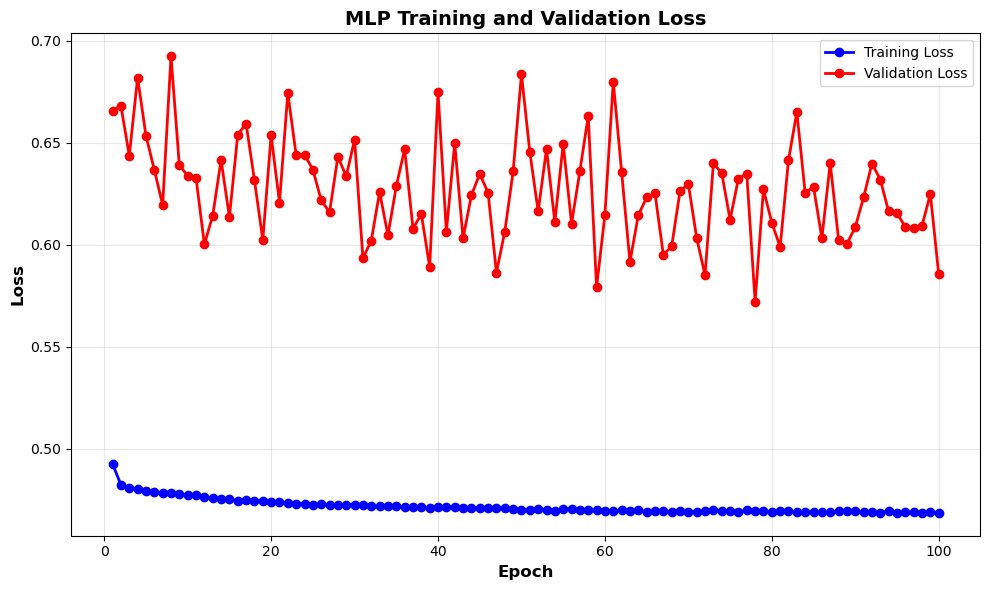

In [32]:
# Train the MLP model
from functions import training

n_epochs = 100
print(f"Training MLP for {n_epochs} epochs...")

train_losses, valid_losses = training(
    n_epochs,
    train_loader,
    valid_loader,
    model_mlp,
    criterion,
    optimizer,
    "model_mlp_diabetes.pt"
)

# Plot training and validation losses
plt.figure(figsize=(10, 6))
plt.plot(range(1, n_epochs + 1), train_losses, 'b-o', label='Training Loss', linewidth=2)
plt.plot(range(1, n_epochs + 1), valid_losses, 'r-o', label='Validation Loss', linewidth=2)
plt.xlabel('Epoch', fontsize=12, fontweight='bold')
plt.ylabel('Loss', fontsize=12, fontweight='bold')
plt.title('MLP Training and Validation Loss', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Evaluate MLP on test set
from functions import evaluation

print("\nEvaluating MLP on test set...")
print("=" * 60)

# Load best model
model_mlp.load_state_dict(torch.load("model_mlp_diabetes.pt"))
evaluation(model_mlp, test_loader, criterion, nb_classes=2)

# Get predictions for comparison with other models
model_mlp.eval()
y_pred_mlp = []
with torch.no_grad():
    for data, _ in test_loader:
        data = data.to(device=device, dtype=torch.float32)
        output = model_mlp(data)
        _, pred = torch.max(output, 1)
        y_pred_mlp.extend(pred.cpu().numpy())

y_pred_mlp = np.array(y_pred_mlp)

# Calculate metrics and add to results
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp, zero_division=0)
mlp_recall = recall_score(y_test, y_pred_mlp, zero_division=0)
mlp_f1 = f1_score(y_test, y_pred_mlp, zero_division=0)

results['MLP (Neural Network)'] = {
    'model': model_mlp,
    'name': 'MLP (Neural Network)',
    'accuracy': mlp_accuracy,
    'precision': mlp_precision,
    'recall': mlp_recall,
    'f1': mlp_f1,
    'y_pred': y_pred_mlp
}

print("\n" + "=" * 60)
print("MLP Metrics:")
print(f"Accuracy:  {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall:    {mlp_recall:.4f}")
print(f"F1-Score:  {mlp_f1:.4f}")


Evaluating MLP on test set...
test Loss: 0.420080

test accuracy of 0: 82% (36019/43667)
test accuracy of 1: 62% (4388/7069)

test accuracy (overall): 79.64% (40407/50736)

MLP Metrics:
Accuracy:  0.7964
Precision: 0.3646
Recall:    0.6207
F1-Score:  0.4594


## 8. Model Comparison and Results

### Recall is Critical for Medical Diagnosis

In medical diagnosis, Recall (Sensitivity) is the most important metric because:

 **False Negative = Missed Diagnosis**: Patient with diabetes told they're healthy → delayed treatment, serious complications
 **False Positive = Extra Testing**: Healthy patient flagged → additional tests can rule it out, no immediate harm

**Better to have false alarms than miss actual cases.**

$$\text{Recall} = \frac{\text{True Positives}}{\text{True Positives + False Negatives}}$$

Measures: "Of all actual diabetes cases, how many did we catch?"

For our dataset, a model which always predicts the patient to have no diabetes would have 87% test accuracy . That's why accuracy is not a good metric to choose here

In [34]:
# Compare models using custom function
# Sort by Recall (most important for medical diagnosis)
comparison_df = compare_models(results, sort_by="Recall")


Model Comparison:

                    Model  Accuracy  Precision   Recall  F1-Score
              Naive Bayes  0.648100   0.261552 0.836752  0.398531
      Logistic Regression  0.730586   0.310432 0.764465  0.441557
Random Forest (Optimized)  0.742195   0.313427 0.714245  0.435672
     MLP (Neural Network)  0.796417   0.364573 0.620738  0.459356
            Random Forest  0.791765   0.356297 0.613099  0.450684
      K-Nearest Neighbors  0.762772   0.317510 0.611260  0.417932


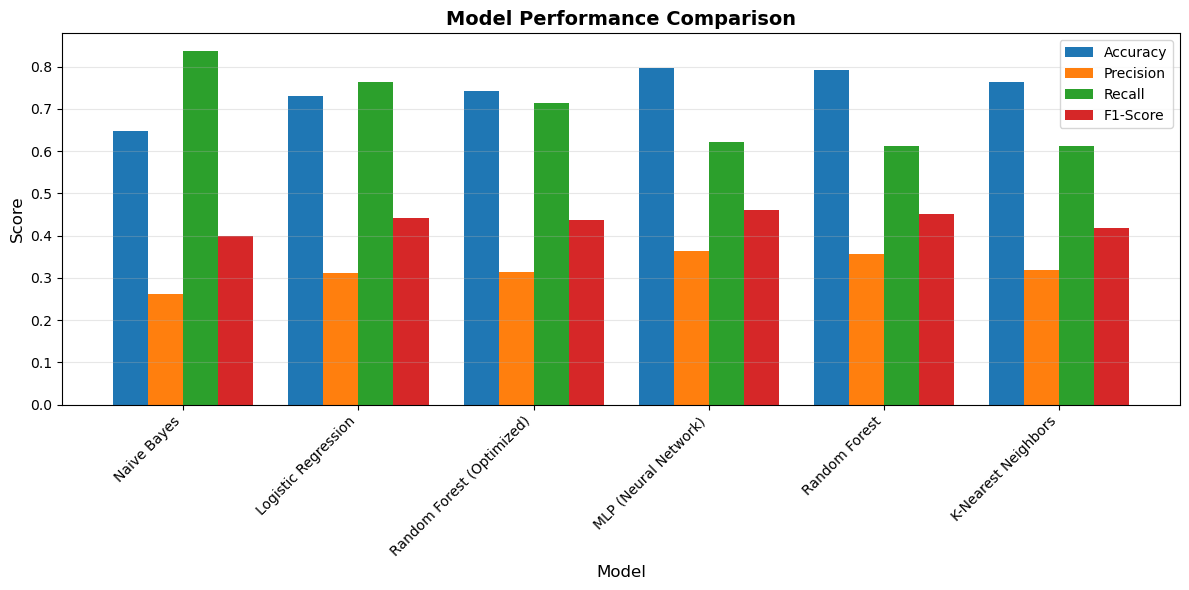

In [35]:
# Visualize model comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Create bar plot with matplotlib
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(comparison_df['Model']))
width = 0.2

for i, metric in enumerate(metrics):
    offset = (i - 1.5) * width
    ax.bar(x + offset, comparison_df[metric], width, label=metric)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

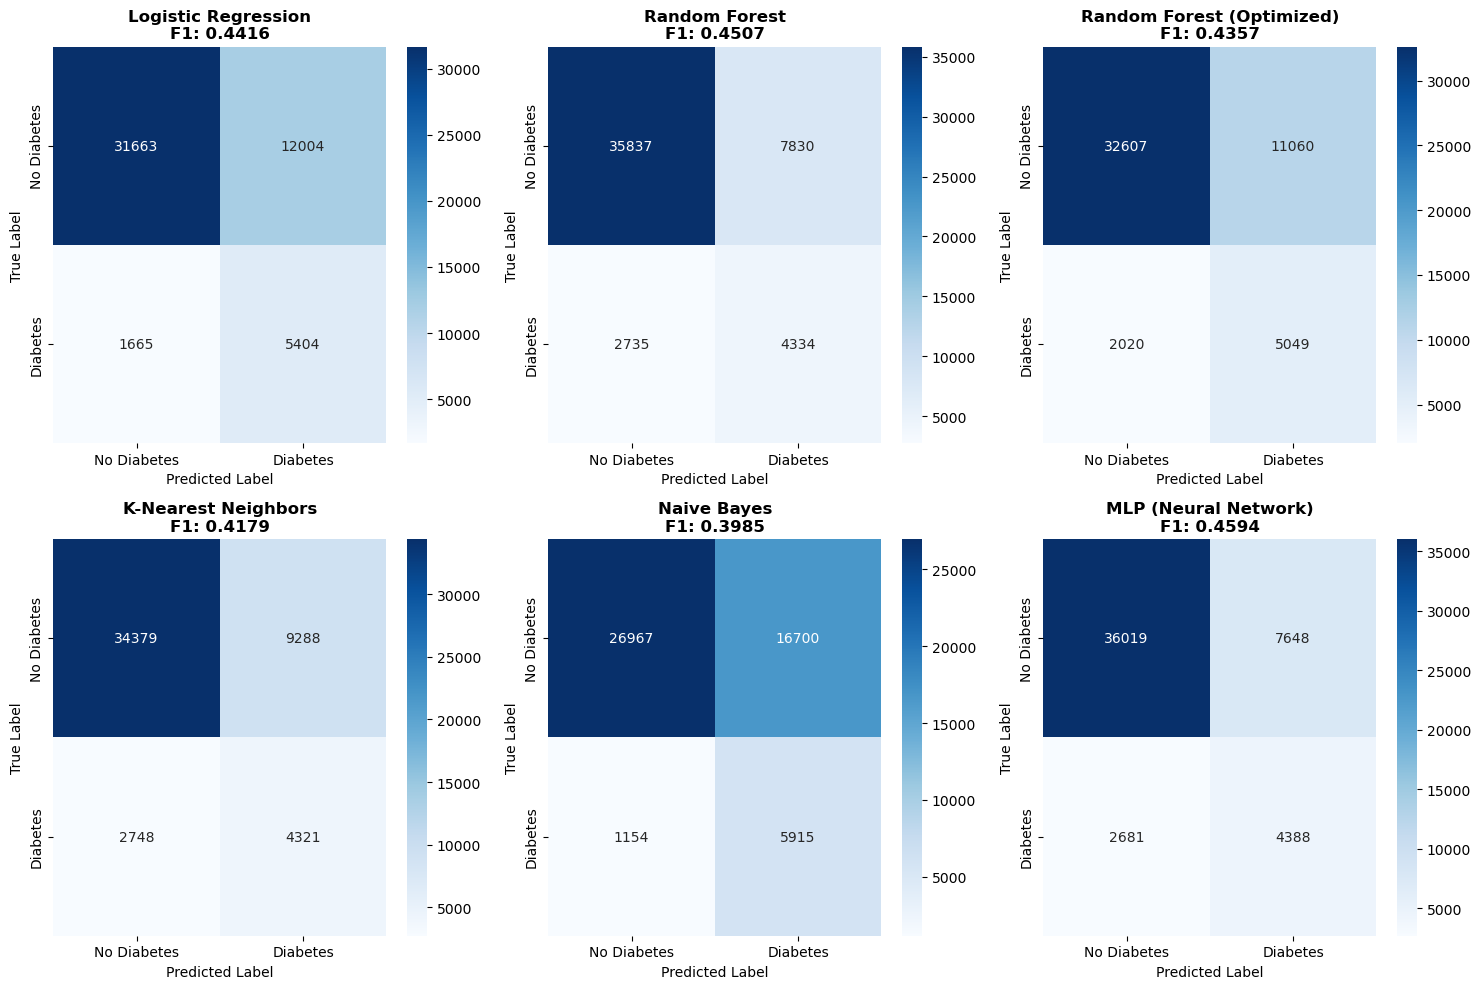

In [36]:
# Confusion matrices for all models
n_models = len(results)
fig, axes = plt.subplots(2, 3, figsize=(15,10))
axes = axes.ravel()

for idx, (name, result) in enumerate(results.items()):
    cm = confusion_matrix(y_test, result['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['No Diabetes', 'Diabetes'],
                yticklabels=['No Diabetes', 'Diabetes'])
    axes[idx].set_title(f'{name}\nF1: {result["f1"]:.4f}', fontweight='bold')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## 9. Conclusion

Based on our comprehensive analysis of diabetes classification using the BRFSS 2015 dataset, **Naive Bayes** emerges as the best model with 83% recall, making it a good choice for medical diagnosis where missing a diabetes case (false negative) has far more serious consequences than flagging a healthy person for additional testing (false positive). While Naive Bayes has lower precision (26%), resulting in more false alarms.